In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/bmw-dataset/bmw.csv


# BMW Used Car Market Analysis & Price Prediction
# Introduction
In this notebook, we perform a comprehensive analysis of the BMW used car market. Our objective is to explore the factors affecting car prices and build machine learning models to predict prices based on features like mileage, engine size, fuel type, and more.

Exploratory Data Analysis (EDA): Understanding the dataset and its distributions.

Data Preprocessing: Handling outliers, cleaning inconsistent data, and encoding categorical features.

Data Visualization: Discovering relationships between variables using Seaborn, Matplotlib, and Altair.

Regression Modeling: Implementing Random Forest and XGBoost.

Model Evaluation: Comparing results using RMSE, MAE, and R² metrics.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv('/kaggle/input/bmw-dataset/bmw.csv')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10781 entries, 0 to 10780
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         10781 non-null  object 
 1   year          10781 non-null  int64  
 2   price         10781 non-null  int64  
 3   transmission  10781 non-null  object 
 4   mileage       10781 non-null  int64  
 5   fuelType      10781 non-null  object 
 6   tax           10781 non-null  int64  
 7   mpg           10781 non-null  float64
 8   engineSize    10781 non-null  float64
dtypes: float64(2), int64(4), object(3)
memory usage: 758.2+ KB


In [5]:
df.isnull().sum()

model           0
year            0
price           0
transmission    0
mileage         0
fuelType        0
tax             0
mpg             0
engineSize      0
dtype: int64

In [6]:
df.describe()

,year,price,mileage,tax,mpg,engineSize
count,10781.000000,10781.000000,10781.000000,10781.000000,10781.000000,10781.000000
mean,2017.078935,22733.408867,25496.986550,131.702068,56.399035,2.167767
std,2.349038,11415.528189,25143.192559,61.510755,31.336958,0.552054
min,1996.000000,1200.000000,1.000000,0.000000,5.500000,0.000000
25%,2016.000000,14950.000000,5529.000000,135.000000,45.600000,2.000000
50%,2017.000000,20462.000000,18347.000000,145.000000,53.300000,2.000000
75%,2019.000000,27940.000000,38206.000000,145.000000,62.800000,2.000000
max,2020.000000,123456.000000,214000.000000,580.000000,470.800000,6.600000


**Observation on Price**

The maximum value in the price column might not be a real value. I will investigate this, otherwise, it might negatively affect machine learning performance.

In [7]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,5 Series,2014,11200,Automatic,67068,Diesel,125,57.6,2.0
1,6 Series,2018,27000,Automatic,14827,Petrol,145,42.8,2.0
2,5 Series,2016,16000,Automatic,62794,Diesel,160,51.4,3.0
3,1 Series,2017,12750,Automatic,26676,Diesel,145,72.4,1.5
4,7 Series,2014,14500,Automatic,39554,Diesel,160,50.4,3.0


# Data Visualization & Cleaning
Visualizing relationships between features helps us understand the data better and identify outliers.

## Relationship between Mileage and Price

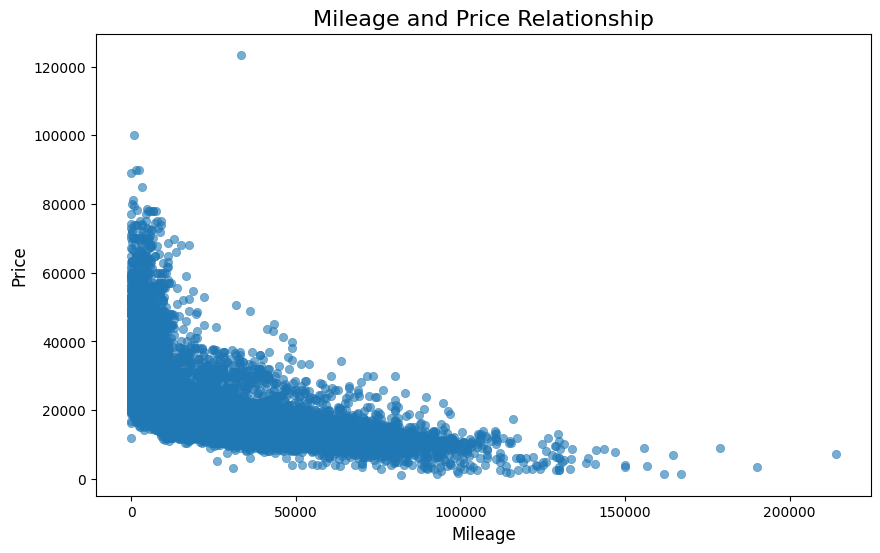

In [8]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='mileage', y='price', alpha=0.6, edgecolor=None)

plt.title('Mileage and Price Relationship', fontsize=16)
plt.xlabel('Mileage', fontsize=12)
plt.ylabel('Price', fontsize=12)
plt.show()

## Handling Outliers 
As seen in the plot above, there is a clear outlier with a very high price. We will remove that value.

In [9]:
# Removing the specific outlier value
df = df[df['price'] != 123456]

## Analyzing Categorical Features
In this section, we will look at object-type values to identify potential inconsistencies.

In [10]:
categorical_cols = df.select_dtypes(include='object').columns
for col in categorical_cols:
    print(f"\nColumn: {col}")
    print(df[col].value_counts().head(20))


Column: model
model
3 Series    2443
1 Series    1969
2 Series    1228
5 Series    1056
4 Series     995
X1           804
X3           551
X5           468
X2           288
X4           179
M4           125
6 Series     108
Z4           108
7 Series     106
X6           106
X7            55
i3            43
8 Series      39
M5            29
M3            27
Name: count, dtype: int64

Column: transmission
transmission
Semi-Auto    4665
Automatic    3588
Manual       2527
Name: count, dtype: int64

Column: fuelType
fuelType
Diesel      7026
Petrol      3417
Hybrid       298
Other         36
Electric       3
Name: count, dtype: int64


## Investigating 'Other' and 'Electric' Fuel Types

In [11]:
other_fuel_cars = df[df['fuelType'] == 'Other']
other_fuel_cars

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
16,3 Series,2017,14250,Automatic,55594,Other,135,148.7,2.0
32,i3,2016,17100,Automatic,25269,Other,0,470.8,0.6
35,2 Series,2017,13000,Automatic,61818,Other,0,141.2,1.5
86,2 Series,2017,16000,Automatic,32389,Other,0,141.2,1.5
118,X5,2016,21000,Automatic,71626,Other,0,85.6,2.0
138,3 Series,2017,17950,Automatic,43703,Other,140,134.5,2.0
152,3 Series,2017,17000,Automatic,31501,Other,0,134.5,2.0
7456,3 Series,2016,17500,Automatic,48000,Other,0,134.5,2.0
8144,5 Series,2018,21940,Automatic,53519,Other,135,156.9,2.0
8188,i3,2015,14940,Automatic,59000,Other,0,470.8,0.6


In [12]:
other_electric_cars = df[df['fuelType'] == 'Electric']
other_electric_cars

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
8375,i3,2017,18999,Automatic,20321,Electric,135,470.8,0.0
8400,i3,2016,18999,Automatic,9990,Electric,0,470.8,0.0
8835,i3,2015,17400,Automatic,29465,Electric,0,470.8,1.0


## Cleaning and Correcting Fuel Types

In [13]:
df['model'] = df['model'].str.strip()
df['fuelType'] = df['fuelType'].str.strip()

In [14]:
df.loc[(df['model'] == 'i3') & (df['fuelType'] == 'Other'), 'fuelType'] = 'Electric'

## Logic to Fill Remaining 'Other' Fuel Types

In [15]:
other_rows = df[df['fuelType'] == 'Other']

for index, row in other_rows.iterrows():
    similar_cars = df[
        (df['model'] == row['model']) & 
        (df['engineSize'] == row['engineSize']) & 
        (df['fuelType'] != 'Other')
    ]
    
    if not similar_cars.empty:
        reference_mpg = similar_cars.groupby('fuelType')['mpg'].mean()
        
        closest_fuel = abs(reference_mpg - row['mpg']).idxmin()
        
        df.at[index, 'fuelType'] = closest_fuel
    else:
        model_only_similar = df[(df['model'] == row['model']) & (df['fuelType'] != 'Other')]
        if not model_only_similar.empty:
            df.at[index, 'fuelType'] = model_only_similar['fuelType'].mode()[0]

print("Operation Successful. New Distribution:")
print(df['fuelType'].value_counts())

Operation Successful. New Distribution:
fuelType
Diesel      7026
Petrol      3417
Hybrid       327
Electric      10
Name: count, dtype: int64


## Distribution Analysis

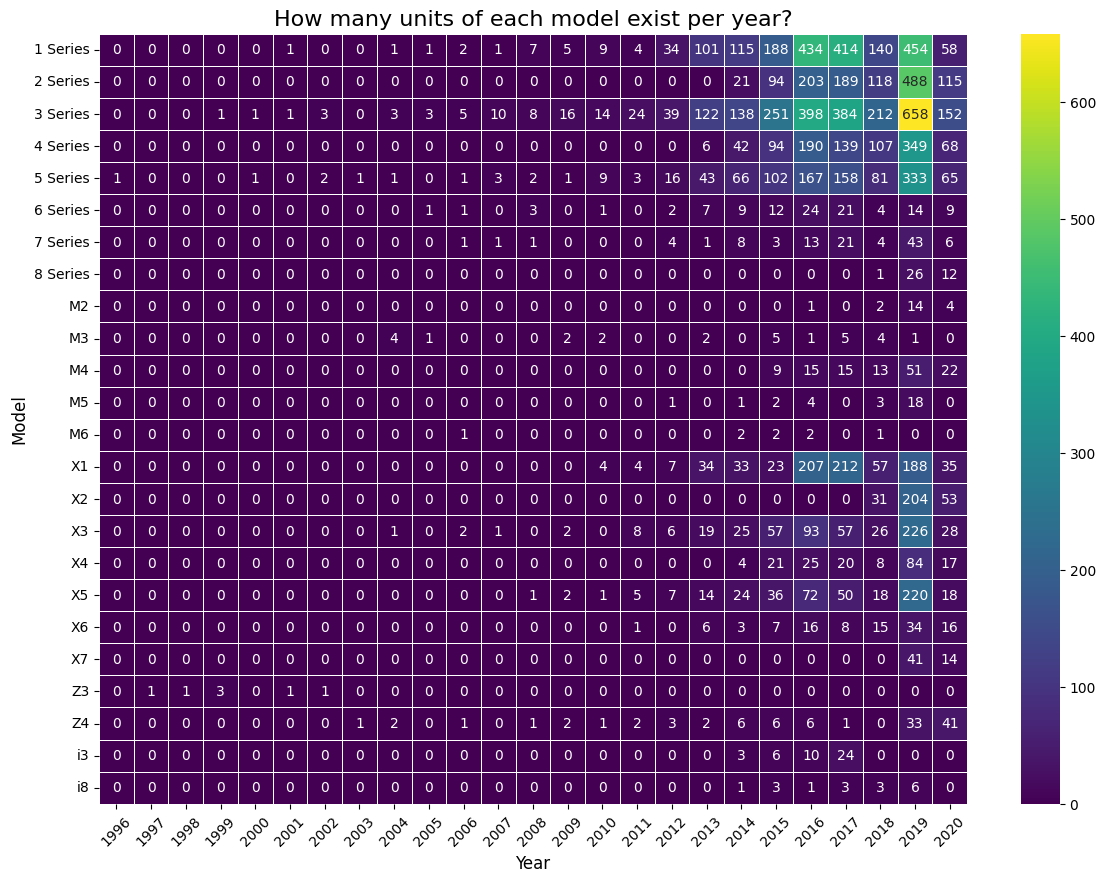

In [16]:
data = df.groupby(['model', 'year']).size().reset_index(name='count')

pivot_table = data.pivot(index='model', columns='year', values='count').fillna(0)

plt.figure(figsize=(14, 10))
sns.heatmap(pivot_table, annot=True, fmt='g', cmap='viridis', linewidths=.5)

plt.title('How many units of each model exist per year?', fontsize=16)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Model', fontsize=12)
plt.xticks(rotation=45)
plt.show()

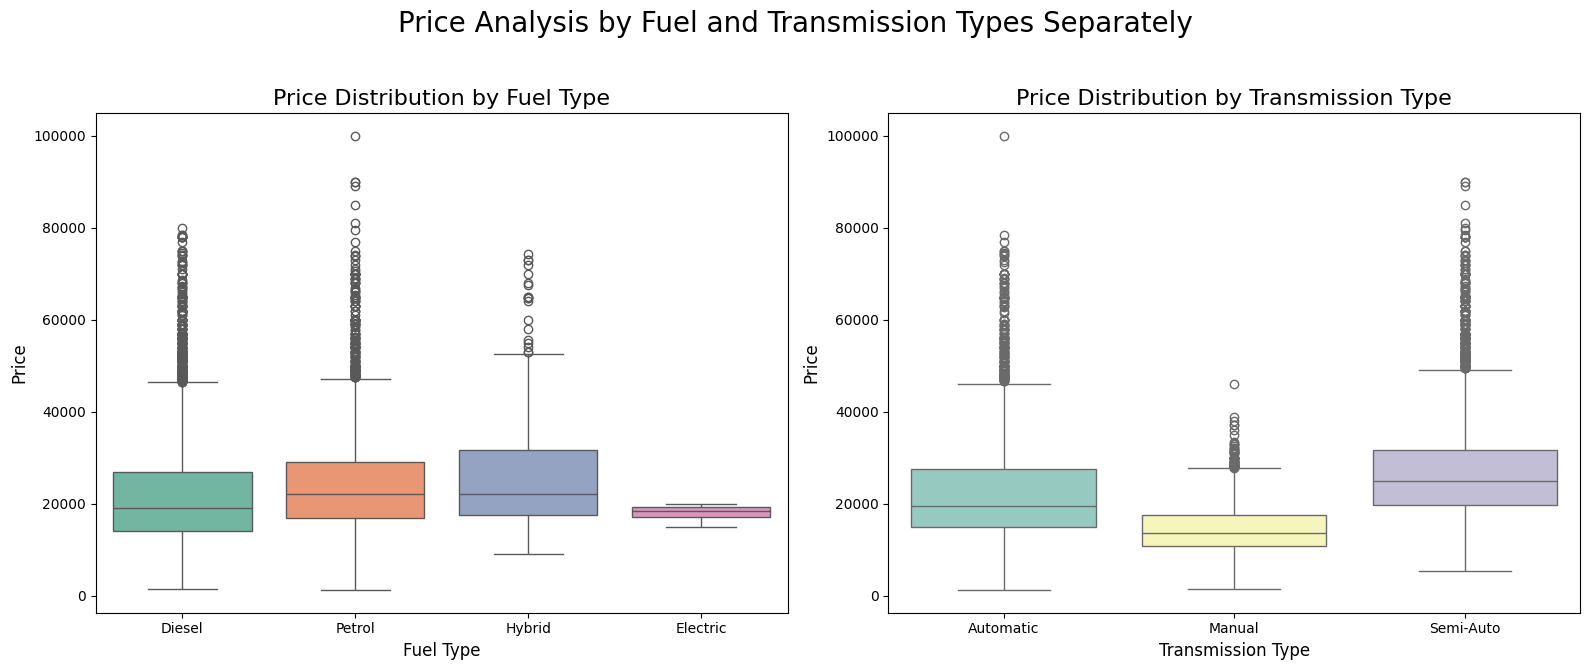

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.boxplot(ax=axes[0], x='fuelType', y='price', data=df, palette='Set2')
axes[0].set_title('Price Distribution by Fuel Type', fontsize=16)
axes[0].set_xlabel('Fuel Type', fontsize=12)
axes[0].set_ylabel('Price', fontsize=12)

sns.boxplot(ax=axes[1], x='transmission', y='price', data=df, palette='Set3')
axes[1].set_title('Price Distribution by Transmission Type', fontsize=16)
axes[1].set_xlabel('Transmission Type', fontsize=12)
axes[1].set_ylabel('Price', fontsize=12)

plt.suptitle('Price Analysis by Fuel and Transmission Types Separately', fontsize=20)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])

plt.show()

## Engine Size vs. Tax Status

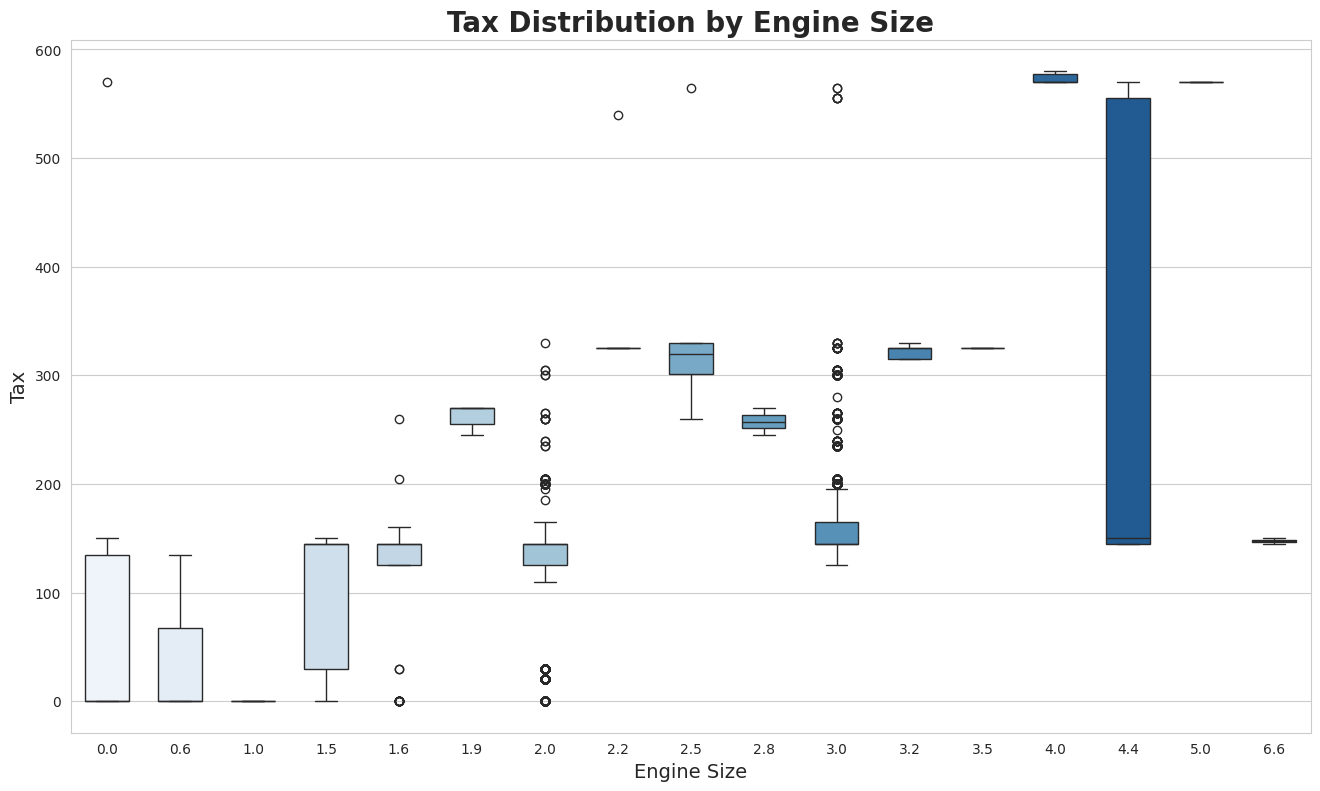

In [18]:
plt.figure(figsize=(16, 9))
sns.set_style("whitegrid")

sns.boxplot(
    data=df, 
    x='engineSize', 
    y='tax', 
    palette='Blues',
    width=0.6
)

plt.title('Tax Distribution by Engine Size', fontsize=20, fontweight='bold')
plt.xlabel('Engine Size', fontsize=14)
plt.ylabel('Tax', fontsize=14)
plt.show()

## Detailed Interactive Model Distribution
Using Altair to visualize details of the top 12 most frequent models.

In [19]:
import altair as alt
alt.renderers.enable('default')
top_12_models = df['model'].value_counts().nlargest(12).index.tolist()

df_top12 = df[df['model'].isin(top_12_models)]

def get_count_summary(series):
    counts = series.value_counts()
    return ', '.join([f"{k}: {v}" for k, v in counts.items()])

summary = df_top12.groupby('model').agg(
    Count=('model', 'count'),
    Year_Range=('year', lambda x: f"{x.min()} - {x.max()}"),
    Price_Range=('price', lambda x: f"{x.min()} - {x.max()}"),
    Engine_Size_Range=('engineSize', lambda x: f"{x.min()} - {x.max()}"),
    Transmission_Dist=('transmission', get_count_summary),
    Fuel_Dist=('fuelType', get_count_summary)
).reset_index()

chart = alt.Chart(summary).mark_arc(outerRadius=220).encode( 
    theta=alt.Theta("Count", stack=True),
    color=alt.Color("model", title="Model", scale=alt.Scale(scheme='category20')),
    order=alt.Order("Count", sort="descending"),
    tooltip=[
        alt.Tooltip("model", title="Model"),
        alt.Tooltip("Count", title="Vehicle Count"),
        alt.Tooltip("Year_Range", title="Year Range"),
        alt.Tooltip("Price_Range", title="Price Range"),
        alt.Tooltip("Engine_Size_Range", title="Engine Size Range"),
        alt.Tooltip("Transmission_Dist", title="Transmission Distribution"),
        alt.Tooltip("Fuel_Dist", title="Fuel Distribution")
    ]
).properties(
    title={
        "text": "Detailed Distribution of Top 12 BMW Models",
        "fontSize": 20,
        "offset": 20
    },
    width=600,   
    height=600  
)

chart

alt.Chart(...)

# Correlation Analysis

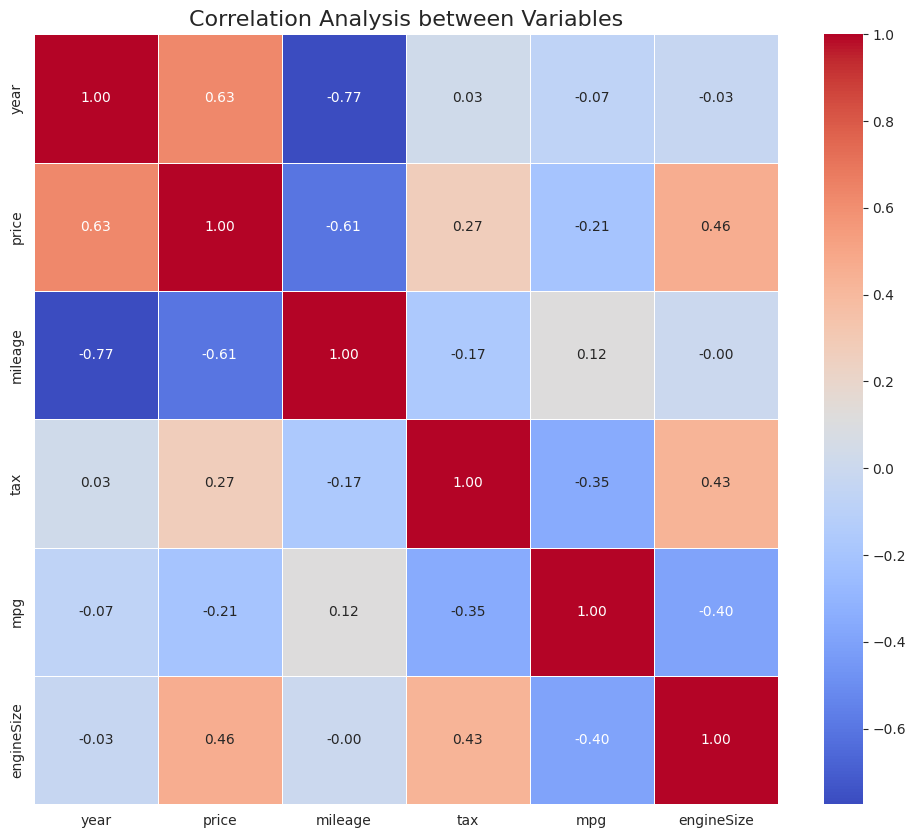

In [20]:
numeric_df = df.select_dtypes(include=[np.number])

corr_matrix = numeric_df.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Analysis between Variables', fontsize=16)
plt.show()

# Data Preprocessing for Machine Learning
We convert categorical variables into numbers using Label Encoding.

In [21]:
from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()

categorical_cols = df_encoded.select_dtypes(include=['object']).columns

le = LabelEncoder()
for col in categorical_cols:
    df_encoded[col] = le.fit_transform(df_encoded[col])
    
    mapping = dict(zip(le.classes_, le.transform(le.classes_)))
    print(f"\nColumn: '{col}'")
    print(f"Example Mappings: {list(mapping.items())[:5]} ...")

print(df_encoded.head())


Column: 'model'
Example Mappings: [('1 Series', np.int64(0)), ('2 Series', np.int64(1)), ('3 Series', np.int64(2)), ('4 Series', np.int64(3)), ('5 Series', np.int64(4))] ...

Column: 'transmission'
Example Mappings: [('Automatic', np.int64(0)), ('Manual', np.int64(1)), ('Semi-Auto', np.int64(2))] ...

Column: 'fuelType'
Example Mappings: [('Diesel', np.int64(0)), ('Electric', np.int64(1)), ('Hybrid', np.int64(2)), ('Petrol', np.int64(3))] ...
   model  year  price  transmission  mileage  fuelType  tax   mpg  engineSize
0      4  2014  11200             0    67068         0  125  57.6         2.0
1      5  2018  27000             0    14827         3  145  42.8         2.0
2      4  2016  16000             0    62794         0  160  51.4         3.0
3      0  2017  12750             0    26676         0  145  72.4         1.5
4      6  2014  14500             0    39554         0  160  50.4         3.0


# Machine Learning Models & Evaluation
We split the data and compare the performance of Random Forest and XGBoost.

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = df_encoded.drop('price', axis=1)  
y = df_encoded['price']               

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

results = []

def train_and_evaluate(model, model_name):
    model.fit(X_train, y_train)
    
    # Predictions
    y_pred = model.predict(X_test)
    
    # Metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse) 
    r2 = r2_score(y_test, y_pred)
    
    # Results
    print(f"--- {model_name} Performance ---")
    print(f"RMSE (Root Mean Squared Error): {rmse:.2f}")
    print(f"MAE  (Mean Absolute Error):   {mae:.2f}")
    print(f"R²   (Success Score):           {r2:.4f}")
    print("-" * 30)
    
    # Add to the list
    results.append({
        'Model': model_name,
        'RMSE': rmse,
        'MAE': mae,
        'R2 Score': r2
    })

#Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
train_and_evaluate(rf_model, "Random Forest")

#XGBoost
xgb_model = XGBRegressor(objective='reg:squarederror', n_estimators=100, random_state=42)
train_and_evaluate(xgb_model, "XGBoost")

# Final Table
results_df = pd.DataFrame(results).sort_values(by='R2 Score', ascending=False)
print("\n=== COMPARISON OF ALL MODELS ===")
print(results_df)

--- Random Forest Performance ---
RMSE (Root Mean Squared Error): 2404.36
MAE  (Mean Absolute Error):   1605.11
R²   (Success Score):           0.9558
------------------------------
--- XGBoost Performance ---
RMSE (Root Mean Squared Error): 2238.64
MAE  (Mean Absolute Error):   1528.86
R²   (Success Score):           0.9617
------------------------------

=== COMPARISON OF ALL MODELS ===
           Model         RMSE          MAE  R2 Score
1        XGBoost  2238.641106  1528.856201  0.961706
0  Random Forest  2404.355964  1605.107955  0.955827


# Conclusion
In this project, we cleaned and analyzed the BMW used car dataset. By handling inconsistent fuel types and outliers, we improved the data quality.

XGBoost and Random Forest models showed high performance in predicting car prices.

Features like Year, Mileage, and Engine Size are critical factors in determining the resale value.